In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("raw_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7657, 19)


,id,name,host_id,host_profile_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,6606,"Fab, private seattle urban cottage!",14942,1462506762321392885,Joyce,Other neighborhoods,Wallingford,47.65444,-122.33629,Entire home/apt,113.0,30.0,161,2024-09-07,0.77,3,177,0,str-opli-19-002622
1,9419,Glorious sun room w/ memory foambed,30559,1462507132280540713,Angielena,Other neighborhoods,Georgetown,47.55017,-122.31937,Private room,86.0,2.0,222,2025-12-20,1.13,10,308,2,Exempt
2,9596,"the down home , spacious, central and fab!",14942,1462506762321392885,Joyce,Other neighborhoods,Wallingford,47.65608,-122.33602,Entire home/apt,NaN,30.0,97,2025-07-31,0.52,3,0,0,STR -OPLI-19-002622
3,11012,"the orange house, quiet 'n central",14942,1462506762321392885,Joyce,Other neighborhoods,Wallingford,47.65405,-122.33744,Entire home/apt,204.0,30.0,98,2021-03-22,0.48,3,178,0,str-opli-19-002622
4,25002,Beautiful Private Spot in North Ballard,102684,1462509654203779028,Amanda,Ballard,Whittier Heights,47.67947,-122.37196,Entire home/apt,121.0,2.0,1199,2026-09-01,6.00,1,218,60,STR-OPLI-19-002617


In [3]:
print("Room Type Counts:")
print(df["room_type"].value_counts())

print("\nMissing Prices:")
print(df["price"].isnull().sum())

print("\nPrice Summary:")
print(df["price"].describe())

Room Type Counts:
room_type
Entire home/apt    6221
Private room       1361
Hotel room           46
Shared room          29
Name: count, dtype: int64

Missing Prices:
1132

Price Summary:
count    6525.000000
mean      277.058697
std       333.690264
min        23.000000
25%       142.000000
50%       225.000000
75%       334.000000
max      9803.000000
Name: price, dtype: float64


In [4]:
df_test = df[
    df["room_type"].isin(["Entire home/apt", "Private room"])
].copy()

df_test = df_test.dropna(subset=["price"])

entire_home = df_test[
    df_test["room_type"] == "Entire home/apt"
]["price"]

private_room = df_test[
    df_test["room_type"] == "Private room"
]["price"]

print("Entire Home Listings:", len(entire_home))
print("Private Room Listings:", len(private_room))

print("\nEntire Home Average Price:", entire_home.mean())
print("Private Room Average Price:", private_room.mean())

Entire Home Listings: 5267
Private Room Listings: 1191

Entire Home Average Price: 298.40896145813554
Private Room Average Price: 170.27959697733


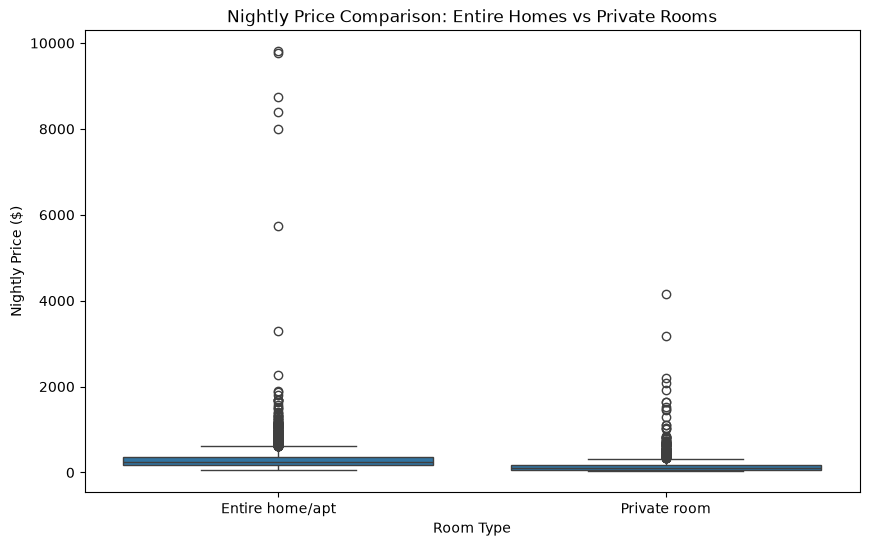

In [5]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_test,
    x="room_type",
    y="price"
)

plt.title("Nightly Price Comparison: Entire Homes vs Private Rooms")
plt.xlabel("Room Type")
plt.ylabel("Nightly Price ($)")
plt.show()

In [6]:
levene_stat, levene_p = stats.levene(
    entire_home,
    private_room,
    center="median"
)

print("Levene's Test Statistic:", levene_stat)
print("Levene's Test P-value:", levene_p)

print("\nEntire Home Price Skewness:", entire_home.skew())
print("Private Room Price Skewness:", private_room.skew())

Levene's Test Statistic: 9.136331413850884
Levene's Test P-value: 0.002515663997597048

Entire Home Price Skewness: 17.67965523158244
Private Room Price Skewness: 7.57939335228065


In [7]:
t_stat, p_value = stats.ttest_ind(
    entire_home,
    private_room,
    equal_var=False
)

print("Welch's T-Test Results")
print("----------------------")
print("T-statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the Null Hypothesis")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis")

Welch's T-Test Results
----------------------
T-statistic: 15.006584488405963
P-value: 1.2055255155864509e-48

Decision: Reject the Null Hypothesis


In [8]:
mean_difference = entire_home.mean() - private_room.mean()

percentage_difference = (
    mean_difference / private_room.mean()
) * 100

print("Mean Price Difference: $", round(mean_difference, 2))
print("Percentage Difference:", round(percentage_difference, 2), "%")

Mean Price Difference: $ 128.13
Percentage Difference: 75.25 %


In [9]:
n1 = len(entire_home)
n2 = len(private_room)
se = np.sqrt(
    (entire_home.var() / n1) +
    (private_room.var() / n2)
)

df_welch = (
    (entire_home.var() / n1 + private_room.var() / n2) ** 2
    /
    (
        (entire_home.var() / n1) ** 2 / (n1 - 1)
        +
        (private_room.var() / n2) ** 2 / (n2 - 1)
    )
)

t_critical = stats.t.ppf(0.975, df_welch)

lower = mean_difference - t_critical * se
upper = mean_difference + t_critical * se

print("Degrees of Freedom:", round(df_welch, 2))
print("95% Confidence Interval:")
print("Lower Bound: $", round(lower, 2))
print("Upper Bound: $", round(upper, 2))

Degrees of Freedom: 2311.0
95% Confidence Interval:
Lower Bound: $ 111.39
Upper Bound: $ 144.87


# Statistical Analysis: Airbnb Nightly Prices in Seattle

## 1. Research Question

Is there a statistically significant difference in average nightly prices between entire-home listings and private-room listings in Seattle?

## 2. Hypotheses

- **Null Hypothesis (H₀):** There is no difference in the average nightly prices between entire-home and private-room listings.
- **Alternative Hypothesis (H₁):** There is a difference in the average nightly prices between entire-home and private-room listings.

Significance level: α = 0.05.

## 3. Dataset Description

The analysis uses the Inside Airbnb Seattle listings dataset.

- Original observations: 7,657
- Original columns: 19
- Entire-home listings with valid prices: 5,267
- Private-room listings with valid prices: 1,191
- Missing prices in the two selected room types excluded: 1,124

Listings with missing prices and listings belonging to hotel-room and shared-room categories were excluded.

## 4. Statistical Method

Welch's independent two-sample t-test was selected because:

- Nightly price is a continuous numerical variable.
- We are comparing the means of two independent groups.
- The two groups have unequal variances.

Welch's test does not require equal population variances.

## 5. Assumption Checking

**Equal variance assumption:**

Levene's test produced a p-value of 0.00252, which is below 0.05. Therefore, the equal variance assumption was rejected.

**Normality and distribution:**

The price distributions were strongly right-skewed.

- Entire-home skewness: 17.68
- Private-room skewness: 7.58

The boxplot also showed several extreme price outliers.

Both groups have large sample sizes, which supports using the Central Limit Theorem for inference about means. However, the extreme skewness and outliers remain important limitations.

Welch's t-test was selected because it accommodates unequal variances, although its results should be interpreted cautiously given the distributions.

## 6. Descriptive Statistics

| Measurement | Entire Home | Private Room |
|---|---:|---:|
| Sample size | 5,267 | 1,191 |
| Average price | $298.41 | $170.28 |

The observed average price difference was $128.13.

## 7. Hypothesis Test Results

Welch's independent two-sample t-test produced:

- T-statistic: 15.0066
- Degrees of freedom: 2311.00
- P-value: 1.2055 × 10⁻⁴⁸
- Significance level: 0.05
- 95% confidence interval: $111.39 to $144.87

Since the p-value is much smaller than 0.05, the null hypothesis is rejected.

There is strong statistical evidence of a difference in average nightly prices between the two listing types.

## 8. Practical Significance

The average nightly price difference was $128.13.

Entire-home listings were approximately 75.25% more expensive than private-room listings in this sample.

This is a substantial observed difference and may be meaningful to people comparing accommodation options.

However, extreme prices can influence averages, so the result should not be interpreted without considering the price distribution.

## 9. Conclusion

The statistical analysis found a significant difference in average nightly prices between entire-home and private-room Airbnb listings in Seattle.

Entire-home listings had an average nightly price of $298.41, compared with $170.28 for private rooms.

The Welch's t-test returned a t-statistic of 15.0066 and a p-value of approximately 1.21 × 10⁻⁴⁸. Since this p-value is below the 0.05 significance level, the null hypothesis was rejected.

The 95% confidence interval suggests that the average price difference lies between $111.39 and $144.87.

In simple terms, entire-home listings were considerably more expensive than private rooms in the analyzed dataset.

This analysis demonstrates a statistically significant association, not a causal relationship. The findings are also subject to limitations from extreme price outliers and skewed distributions.